In [ ]:
!pip -q install pandas numpy scikit-learn matplotlib seaborn joblib

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    average_precision_score
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
from google.colab import files

uploaded = files.upload()

file_name = next(iter(uploaded))

df = pd.read_csv(file_name)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Saving student_model_data.csv to student_model_data.csv
Dataset loaded successfully!
Dataset shape: (32593, 24)


,code_module,code_presentation,id_student,final_result,at_risk,gender,region,highest_education,imd_band,age_band,...,assessments_due_by_day30,assessments_submitted_by_day30,early_assessment_mean_score,early_assessment_score_count,last_submission_day,assessments_due_submitted_by_day30,missed_assessments_by_day30,vle_clicks_first30,vle_active_days_first30,vle_unique_sites_first30
0,AAA,2013J,11391,Pass,0,M,East Anglian Region,HE Qualification,90-100%,55<=,...,1.0,1.0,78.0,1.0,18.0,1.0,0.0,326.0,9.0,26.0
1,AAA,2013J,28400,Pass,0,F,Scotland,HE Qualification,20-30%,35-55,...,1.0,1.0,70.0,1.0,22.0,1.0,0.0,403.0,12.0,25.0
2,AAA,2013J,30268,Withdrawn,1,F,North Western Region,A Level or Equivalent,30-40%,35-55,...,1.0,0.0,NaN,0.0,NaN,0.0,1.0,179.0,6.0,17.0
3,AAA,2013J,31604,Pass,0,F,South East Region,A Level or Equivalent,50-60%,35-55,...,1.0,1.0,72.0,1.0,17.0,1.0,0.0,371.0,19.0,23.0
4,AAA,2013J,32885,Pass,0,F,West Midlands Region,Lower Than A Level,50-60%,0-35,...,1.0,1.0,69.0,1.0,26.0,1.0,0.0,272.0,16.0,18.0


In [ ]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 32593
Number of columns: 24


In [ ]:
print(df.columns.tolist())

['code_module', 'code_presentation', 'id_student', 'final_result', 'at_risk', 'gender', 'region', 'highest_education', 'imd_band', 'age_band', 'num_of_prev_attempts', 'studied_credits', 'disability', 'date_registration', 'assessments_due_by_day30', 'assessments_submitted_by_day30', 'early_assessment_mean_score', 'early_assessment_score_count', 'last_submission_day', 'assessments_due_submitted_by_day30', 'missed_assessments_by_day30', 'vle_clicks_first30', 'vle_active_days_first30', 'vle_unique_sites_first30']


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32593 entries, 0 to 32592
Data columns (total 24 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   code_module                         32593 non-null  object 
 1   code_presentation                   32593 non-null  object 
 2   id_student                          32593 non-null  int64  
 3   final_result                        32593 non-null  object 
 4   at_risk                             32593 non-null  int64  
 5   gender                              32593 non-null  object 
 6   region                              32593 non-null  object 
 7   highest_education                   32593 non-null  object 
 8   imd_band                            31482 non-null  object 
 9   age_band                            32593 non-null  object 
 10  num_of_prev_attempts                32593 non-null  int64  
 11  studied_credits                     32593

In [ ]:
missing_values = df.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": (
        missing_values / len(df) * 100
    ).round(2)
})

missing_summary = missing_summary.sort_values(
    by="Missing Percentage",
    ascending=False
)

display(missing_summary)

,Missing Values,Missing Percentage
early_assessment_mean_score,12533,38.45
last_submission_day,12520,38.41
imd_band,1111,3.41
date_registration,45,0.14
code_module,0,0.00
code_presentation,0,0.00
id_student,0,0.00
final_result,0,0.00
highest_education,0,0.00
region,0,0.00


In [ ]:
print("Exact duplicate rows:", df.duplicated().sum())

Exact duplicate rows: 0


In [ ]:
print(df["at_risk"].value_counts())

print("\nTarget percentages:")
print(
    (df["at_risk"].value_counts(normalize=True) * 100)
    .round(2)
)

at_risk
1    17208
0    15385
Name: count, dtype: int64

Target percentages:
at_risk
1    52.8
0    47.2
Name: proportion, dtype: float64


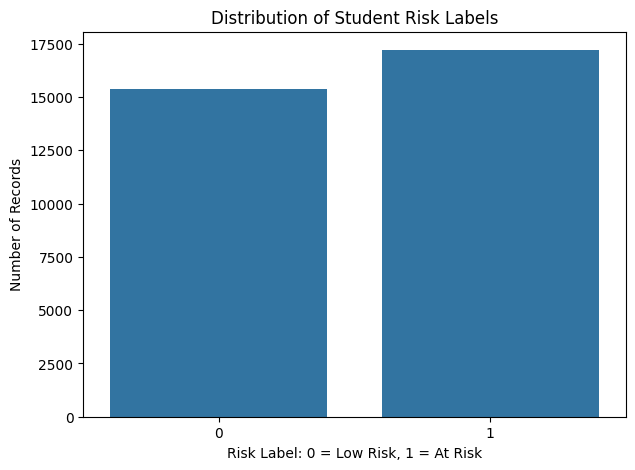

In [ ]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="at_risk"
)

plt.title("Distribution of Student Risk Labels")
plt.xlabel("Risk Label: 0 = Low Risk, 1 = At Risk")
plt.ylabel("Number of Records")

plt.show()

In [ ]:
target = "at_risk"

In [ ]:
TARGET = "at_risk"

excluded_columns = [
    "at_risk",
    "final_result",
    "id_student",
    "last_submission_day",
    "gender",
    "region",
    "highest_education",
    "imd_band",
    "age_band",
    "disability"
]

X = df.drop(columns=excluded_columns)
y = df[TARGET].astype(int)

print("Input feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeatures used:")
print(X.columns.tolist())

print("\nTarget classes:")
print(y.value_counts())

Input feature shape: (32593, 14)
Target shape: (32593,)

Features used:
['code_module', 'code_presentation', 'num_of_prev_attempts', 'studied_credits', 'date_registration', 'assessments_due_by_day30', 'assessments_submitted_by_day30', 'early_assessment_mean_score', 'early_assessment_score_count', 'assessments_due_submitted_by_day30', 'missed_assessments_by_day30', 'vle_clicks_first30', 'vle_active_days_first30', 'vle_unique_sites_first30']

Target classes:
at_risk
1    17208
0    15385
Name: count, dtype: int64


In [ ]:
numeric_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['num_of_prev_attempts', 'studied_credits', 'date_registration', 'assessments_due_by_day30', 'assessments_submitted_by_day30', 'early_assessment_mean_score', 'early_assessment_score_count', 'assessments_due_submitted_by_day30', 'missed_assessments_by_day30', 'vle_clicks_first30', 'vle_active_days_first30', 'vle_unique_sites_first30']

Categorical features:
['code_module', 'code_presentation']


In [ ]:
numeric_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)

categorical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "encoder",
            OneHotEncoder(handle_unknown="ignore")
        )
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numeric_transformer,
            numeric_features
        ),
        (
            "cat",
            categorical_transformer,
            categorical_features
        )
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).round(3))

Training records: 26074
Testing records: 6519

Training target distribution:
at_risk
1    0.528
0    0.472
Name: proportion, dtype: float64

Testing target distribution:
at_risk
1    0.528
0    0.472
Name: proportion, dtype: float64


In [ ]:
logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                max_iter=2000,
                class_weight="balanced",
                random_state=42
            )
        )
    ]
)

logistic_model.fit(X_train, y_train)

print("Logistic Regression training completed!")

Logistic Regression training completed!


In [ ]:
y_pred_lr = logistic_model.predict(X_test)

y_prob_lr = logistic_model.predict_proba(X_test)[:, 1]

print("First 10 predictions:")
print(y_pred_lr[:10])

print("\nFirst 10 predicted risk probabilities:")
print(y_prob_lr[:10].round(3))

First 10 predictions:
[0 0 1 0 0 0 0 1 0 0]

First 10 predicted risk probabilities:
[0.349 0.42  0.527 0.345 0.248 0.229 0.445 0.991 0.457 0.254]


In [ ]:
def evaluate_model(model_name, y_true, y_pred, y_prob):
    results = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "F1 Score": f1_score(
            y_true, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_true, y_prob),
        "Average Precision": average_precision_score(
            y_true, y_prob
        )
    }

    return results


lr_results = evaluate_model(
    "Logistic Regression",
    y_test,
    y_pred_lr,
    y_prob_lr
)

print(pd.Series(lr_results))

Model                Logistic Regression
Accuracy                        0.744439
Precision                       0.810924
Recall                          0.672865
F1 Score                        0.735472
ROC-AUC                         0.821384
Average Precision               0.851892
dtype: object


In [ ]:
print(
    classification_report(
        y_test,
        y_pred_lr,
        target_names=["Low Risk", "At Risk"],
        zero_division=0
    )
)

              precision    recall  f1-score   support

    Low Risk       0.69      0.82      0.75      3077
     At Risk       0.81      0.67      0.74      3442

    accuracy                           0.74      6519
   macro avg       0.75      0.75      0.74      6519
weighted avg       0.76      0.74      0.74      6519



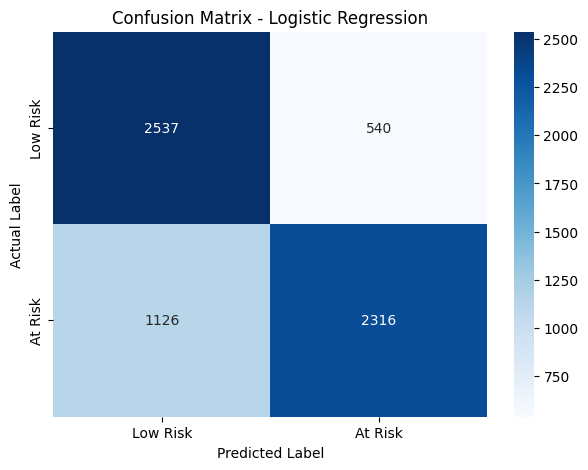

In [ ]:
cm = confusion_matrix(
    y_test,
    y_pred_lr,
    labels=[0, 1]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Low Risk", "At Risk"],
    yticklabels=["Low Risk", "At Risk"]
)

plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.show()

In [ ]:
rf_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=200,
                max_depth=15,
                min_samples_split=10,
                min_samples_leaf=4,
                class_weight="balanced",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

rf_model.fit(X_train, y_train)

print("Random Forest training completed!")

Random Forest training completed!


In [ ]:
y_pred_rf = rf_model.predict(X_test)

y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

print("First 10 predictions:")
print(y_pred_rf[:10])

print("\nFirst 10 risk probabilities:")
print(y_prob_rf[:10].round(3))

First 10 predictions:
[0 0 1 0 0 0 1 1 0 0]

First 10 risk probabilities:
[0.301 0.283 0.642 0.205 0.225 0.23  0.51  0.978 0.32  0.344]


In [ ]:
rf_results = evaluate_model(
    "Random Forest",
    y_test,
    y_pred_rf,
    y_prob_rf
)

print(pd.Series(rf_results))

Model                Random Forest
Accuracy                  0.765762
Precision                 0.834907
Recall                    0.693492
F1 Score                  0.757658
ROC-AUC                   0.841267
Average Precision         0.876009
dtype: object


In [ ]:
results_df = pd.DataFrame([
    lr_results,
    rf_results
])

results_df = results_df.sort_values(
    by="Recall",
    ascending=False
)

display(
    results_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1 Score": "{:.4f}",
        "ROC-AUC": "{:.4f}",
        "Average Precision": "{:.4f}"
    })
)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Average Precision
1,Random Forest,0.7658,0.8349,0.6935,0.7577,0.8413,0.8760
0,Logistic Regression,0.7444,0.8109,0.6729,0.7355,0.8214,0.8519


In [ ]:
from sklearn.model_selection import GroupShuffleSplit

groups = df.loc[X.index, "id_student"]

group_splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    group_splitter.split(X, y, groups=groups)
)

X_train_group = X.iloc[train_idx]
X_test_group = X.iloc[test_idx]

y_train_group = y.iloc[train_idx]
y_test_group = y.iloc[test_idx]

print("Training records:", len(X_train_group))
print("Testing records:", len(X_test_group))

train_students = set(groups.iloc[train_idx])
test_students = set(groups.iloc[test_idx])

print(
    "Students appearing in both sets:",
    len(train_students.intersection(test_students))
)

Training records: 26122
Testing records: 6471
Students appearing in both sets: 0


In [ ]:
group_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=200,
                max_depth=15,
                min_samples_split=10,
                min_samples_leaf=4,
                class_weight="balanced",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

group_model.fit(
    X_train_group,
    y_train_group
)

group_predictions = group_model.predict(
    X_test_group
)

group_probabilities = group_model.predict_proba(
    X_test_group
)[:, 1]

print(
    classification_report(
        y_test_group,
        group_predictions,
        target_names=["Low Risk", "At Risk"],
        zero_division=0
    )
)

print(
    "Student-grouped ROC-AUC:",
    round(
        roc_auc_score(
            y_test_group,
            group_probabilities
        ),
        4
    )
)

              precision    recall  f1-score   support

    Low Risk       0.70      0.84      0.76      3073
     At Risk       0.83      0.67      0.74      3398

    accuracy                           0.75      6471
   macro avg       0.76      0.76      0.75      6471
weighted avg       0.76      0.75      0.75      6471

Student-grouped ROC-AUC: 0.8342


In [ ]:
if rf_results["Recall"] >= lr_results["Recall"]:
    best_model = rf_model
    best_model_name = "Random Forest"
else:
    best_model = logistic_model
    best_model_name = "Logistic Regression"

print("Selected model:", best_model_name)

joblib.dump(
    best_model,
    "student_risk_model.joblib"
)

print("Model saved successfully!")

Selected model: Random Forest
Model saved successfully!


In [33]:
from google.colab import files

files.download("student_risk_model.joblib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
def generate_recommendation(student_data, risk_probability):
    recommendations = []

    if (
        student_data["missed_assessments_by_day30"].iloc[0]
        > 0
    ):
        recommendations.append(
            "Review missed assessments and offer a catch-up plan."
        )

    if (
        student_data["vle_active_days_first30"].iloc[0]
        < 5
    ):
        recommendations.append(
            "Check whether the student can access and use "
            "the online learning platform."
        )

    if (
        pd.isna(
            student_data[
                "early_assessment_mean_score"
            ].iloc[0]
        )
    ):
        recommendations.append(
            "Check whether the student has completed an "
            "early assessment or needs assistance."
        )

    if risk_probability >= 0.5:
        recommendations.append(
            "Offer a supportive check-in and discuss "
            "possible academic difficulties."
        )
    else:
        recommendations.append(
            "Continue regular monitoring and provide "
            "access to learning resources."
        )

    return recommendations

# Select a valid sample student from the test set
sample_student = X_test.iloc[[0]]

# Calculate the risk probability using the selected best model
probability = best_model.predict_proba(sample_student)[0, 1]

# Generate and print the recommendations
recommendations = generate_recommendation(
    sample_student,
    probability
)

print(f"Sample Student Risk Probability: {probability:.3f}")
print("\nSuggested early-support actions:\n")

for item in recommendations:
    print("-", item)

Sample Student Risk Probability: 0.300

Suggested early-support actions:

- Continue regular monitoring and provide access to learning resources.


In [36]:
sample_student = X_test.iloc[[0]]

prediction = best_model.predict(
    sample_student
)[0]

probability = best_model.predict_proba(
    sample_student
)[0, 1]

print("Predicted risk:", prediction)
print(
    "Estimated risk probability:",
    round(probability * 100, 2),
    "%"
)

if prediction == 1:
    print("Category: At Risk")
else:
    print("Category: Low Risk")

Predicted risk: 0
Estimated risk probability: 29.96 %
Category: Low Risk


In [37]:
import joblib

# Re-save the best trained model to the compressed path requested by the user
joblib.dump(
    best_model,
    "/content/student_risk_model_compressed.joblib",
    compress=3
)

print("Model successfully trained and saved to /content/student_risk_model_compressed.joblib!")

Model successfully trained and saved to /content/student_risk_model_compressed.joblib!


In [38]:
# Test loading the newly saved compressed model to verify it loads without any errors
test_load_model = joblib.load("/content/student_risk_model_compressed.joblib")
print("Verified: Model loaded successfully from compressed file!")
print("Loaded Model Type:", type(test_load_model))

Verified: Model loaded successfully from compressed file!
Loaded Model Type: <class 'sklearn.pipeline.Pipeline'>
